# 11 — Telco: From probabilities to a retention decision
**Session 6 · Objective:** Select cutoffs on validation, compare fixed policies on holdout, quantify conditional uncertainty and design a real policy experiment.

The reference is **do nothing / no offers = zero incremental contribution**. These are scenario-based expected contributions, not observed causal campaign profits. We compare original-input Logistic Regression with Logistic Regression plus two logs, using a validation-selected correction for the latter.

In [1]:
# Locate the course CSV relative to this notebook, on any operating system.
from pathlib import Path
# Verify that we are using exactly the same CSV bytes as the classroom.
import hashlib
# Report the Python version alongside the numerical results.
import platform
# Work with probability arrays, logarithms and reproducible random samples.
import numpy as np
# Keep customer data and result tables labelled by meaningful column names.
import pandas as pd
# Build the plots step by step, with explicit axes and units.
import matplotlib.pyplot as plt
# Report the installed learning-library version for reproducibility.
import sklearn
# Display more than one table from the same cell.
from IPython.display import display
# Create a fresh, unfitted copy of a model before another training run.
from sklearn.base import clone
# Apply different preprocessing to numeric and categorical inputs.
from sklearn.compose import ColumnTransformer
# Learn missing-value replacements from training customers only.
from sklearn.impute import SimpleImputer
# Keep the Logistic Regression algorithm fixed while testing inputs or policies.
from sklearn.linear_model import LogisticRegression
# Split customers reproducibly and keep churn proportions similar across folds.
from sklearn.model_selection import train_test_split, StratifiedKFold
# Fit preprocessing and the classifier within the same training boundary.
from sklearn.pipeline import Pipeline

# Scale measured quantities, encode categories and apply row-wise log formulas.
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Evaluate ranking with Average Precision rather than accuracy at an arbitrary cutoff.
from sklearn.metrics import average_precision_score

# Fit probability corrections on fitting folds without using validation outcomes.
from sklearn.calibration import CalibratedClassifierCV
# Measure probability error separately from ranking quality.
from sklearn.metrics import brier_score_loss, roc_auc_score

In [2]:
# Print the actual environment; do not assume it matches the instructor's versions.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__})
# Use readable default figures and remove the two unnecessary border lines.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

# Show campaign euros in full instead of scientific notation.
pd.options.display.float_format = '{:,.4f}'.format

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}


## Rebuild the classroom experiment
Notebook 03 reserved a 20% holdout; notebooks 06–08 kept it closed. Session 6 introduces its evaluation **after** calibration and policy choices on validation. The classroom materials already inspected this holdout: this reproduction is not a new, untouched confirmation.

Split development again into fitting and validation. Calibration uses five shuffled stratified folds **inside fitting only**, seed 606, `ensemble=False`: out-of-fold scores train the correction and the base estimator is refitted on all fitting rows. Validation chooses the correction and cutoffs. Refit on development later, keeping those choices fixed.

The SHA-256 below matches the v4 evidence file byte for byte. Numeric parsing is row-wise; medians, scales and categories are learned inside each Pipeline. Sample sizes and bin support stay in actual customers. Campaign totals are displayed per million of the corresponding population; extrapolation creates no extra observations.

In [3]:
# Point from notebooks/ to the CSV committed with this repository.
data_path = Path('../data/telco.csv')
# Fingerprint the file before cleaning so byte-for-byte identity can be checked.
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
# This reference identifies the dataset; it is not a fitted result.
class_fingerprint = '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a'
# Stop if the dataset changed instead of silently comparing incompatible figures.
assert fingerprint == class_fingerprint, 'Dataset differs from class; investigate first.'
# Keep the verified fingerprint visible in the saved output.
print('Dataset SHA-256:', fingerprint)
# Load one row per customer.
df = pd.read_csv(data_path)
# Confirm the expected size and that customers have not been duplicated.
assert df.shape == (7043, 21) and df.customerID.is_unique
# Parse each charge independently; the eleven blank strings become missing values.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# Exclude both the answer and the identifier from the model inputs.
X = df.drop(columns=['Churn', 'customerID'])
# Encode observed churn as 1 and staying as 0.
y = df['Churn'].eq('Yes').astype(int)

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a


In [4]:
# Reserve the same 20% holdout as notebook 03 before fitting any transformation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=42
)
# Use validation to choose corrections and cutoffs; keep fitting customers separate.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=.30, stratify=y_dev, random_state=606
)
# Check the four sample sizes from the classroom protocol.
assert (len(X_dev), len(X_test), len(X_fit), len(X_valid)) == (5634, 1409, 3943, 1691)
# Check that fitting and validation do not share customers.
assert set(X_fit.index).isdisjoint(X_valid.index)
# Check that the holdout stays outside all development decisions.
assert set(X_dev.index).isdisjoint(X_test.index)
# Check that the inner split accounts for every development customer exactly once.
assert set(X_fit.index) | set(X_valid.index) == set(X_dev.index)
# Check input/outcome order at each boundary before converting anything to arrays.
for features, labels in [(X_fit, y_fit), (X_valid, y_valid), (X_test, y_test)]:
    # Equal indices mean row i describes the same customer on both sides.
    assert features.index.equals(labels.index)
# Display actual sample sizes; these are not extrapolated campaign counts.
display(pd.Series({'Development n': len(X_dev), 'Holdout n': len(X_test),
                   'Fitting n': len(X_fit), 'Validation n': len(X_valid)}))

Development n    5634
Holdout n        1409
Fitting n        3943
Validation n     1691
dtype: int64

## Hold the algorithm fixed; change two inputs
The first model uses original inputs. The finalist retains them and adds `log1p(tenure)` and `log1p(TotalCharges)`. These row-wise logs express diminishing changes and learn no population statistics. This is **not** notebook 07's Logistic +logs versus XGBoost +polynomials comparison. `SeniorCitizen` is categorical despite its 0/1 storage.

In [5]:
# Name the measured quantities explicitly; SeniorCitizen is a category, not a measurement.
NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Collect all remaining original inputs as categorical columns.
CATEGORICAL = []
# Inspect each original column rather than inferring its role from its storage type.
for column in X.columns:
    # Anything outside the three measured quantities is one-hot encoded.
    if column not in NUMERIC:
        # Retain column order so the transformed model inputs stay reproducible.
        CATEGORICAL.append(column)
# Make the course's treatment of the stored 0/1 field explicit.
assert 'SeniorCitizen' in CATEGORICAL

# Define only the row-wise formula; it learns no statistics from other customers.
def add_logs(frame):
    # Copy inputs so another candidate can still use the original columns unchanged.
    result = frame.copy()
    # Compress tenure changes while allowing tenure zero: log1p(x) means log(1 + x).
    result['log_tenure'] = np.log1p(result['tenure'])
    # Missing total charges remain missing until the training imputer handles them.
    result['log_total'] = np.log1p(result['TotalCharges'])
    # Return originals plus the two added inputs.
    return result

In [6]:
# Rebuild an unfitted Pipeline each time so candidates do not share learned statistics.
def build_model(logs=False):
    # Begin with the original three measured quantities.
    numeric_columns = list(NUMERIC)
    # The baseline passes original inputs straight through.
    feature_step = 'passthrough'
    # Add logs only for the augmented candidate, retaining the original inputs.
    if logs:
        # Route the two derived numeric columns through the numeric branch too.
        numeric_columns.extend(['log_tenure', 'log_total'])
        # Adapt the simple row-wise function to the Pipeline's fit/transform interface.
        feature_step = FunctionTransformer(add_logs)
    # Learn numeric replacements and scales inside each training partition.
    numeric_preprocessing = Pipeline([
        ('impute', SimpleImputer(strategy='median')),  # Training medians replace missing values.
        ('scale', StandardScaler())  # Training means and standard deviations set the scale.
    ])
    # Keep categorical encoding separate from measured quantities.
    preprocessing = ColumnTransformer([
        ('num', numeric_preprocessing, numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL)
    ])
    # Keep the regularization and optimizer identical for the two candidates.
    classifier = LogisticRegression(C=1, solver='lbfgs', max_iter=2000)
    # Fit the feature step, preprocessing and classifier within the same boundary.
    return Pipeline([('features', feature_step), ('preprocess', preprocessing),
                     ('model', classifier)])

## Fix the probability method on validation
Neither holdout outcomes nor subgroup diagnostics choose the method here. We reproduce the same fitting-only calibration and validation Brier rule as notebook 09.

In [7]:
# Fit the original-input reference using fitting customers only.
models = {}
# A separate Pipeline prevents learned preprocessing from being shared across models.
models['original'] = build_model(False).fit(X_fit, y_fit)
# Fit the augmented model before applying any probability correction.
models['raw'] = build_model(True).fit(X_fit, y_fit)
# Keep calibration folds entirely inside fitting, not validation.
cv = StratifiedKFold(5, shuffle=True, random_state=606)
# Audit each internal split before fitting the corrections.
for train_positions, calibration_positions in cv.split(X_fit, y_fit):
    # No customer may train the base model that produces their calibration-fold score.
    assert set(train_positions).isdisjoint(calibration_positions)
# Fit each correction from out-of-fold fitting scores, then refit its base model on fitting.
for method in ['sigmoid', 'isotonic']:
    # ensemble=False gives a single refitted base estimator and its learned correction.
    calibrated_model = CalibratedClassifierCV(
        build_model(True), method=method, cv=cv, ensemble=False
    )
    # Validation labels never enter this fit.
    models[method] = calibrated_model.fit(X_fit, y_fit)

In [8]:
# Store one aligned probability array per model for the same validation customers.
prob_valid = {}
# Collect readable metric rows instead of nesting table-building comprehensions.
metric_rows = []
# Score every fitted candidate without refitting on validation.
for name, model in models.items():
    # Column 1 is the probability of the churn class, not a binary decision.
    probabilities = model.predict_proba(X_valid)[:, 1]
    # Keep these probabilities for bin diagnostics and policy comparisons.
    prob_valid[name] = probabilities
    # Check customer count before pairing predictions with outcomes.
    assert len(probabilities) == len(y_valid)
    # Reject missing, infinite or out-of-range probabilities.
    assert np.isfinite(probabilities).all()
    # All numerical probability values must lie between zero and one.
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    # Compute probability error and two ranking summaries on identical customers.
    metric_rows.append({'Model': name,
                        'Brier': brier_score_loss(y_valid, probabilities),
                        'AP': average_precision_score(y_valid, probabilities),
                        'ROC AUC': roc_auc_score(y_valid, probabilities)})
# Put model names on the table's row labels.
validation_metrics = pd.DataFrame(metric_rows).set_index('Model')
# Start with raw probabilities so an exact tie keeps the simpler method.
selected_method = 'raw'
# Consider corrections in a fixed order without letting holdout results choose one.
for method in ['sigmoid', 'isotonic']:
    # Replace the current choice only if validation Brier is strictly smaller.
    if validation_metrics.loc[method, 'Brier'] < validation_metrics.loc[selected_method, 'Brier']:
        # Remember the validation choice for later refitting, not the fitted weights.
        selected_method = method
# Show all candidates, including corrections that fail to improve probability quality.
display(validation_metrics.round(6))
# Make the fixed selection visible before any holdout evaluation.
print('Validation choice:', selected_method)

,Brier,AP,ROC AUC
Model,,,
original,0.1318,0.6656,0.8567
raw,0.1296,0.6757,0.8615
sigmoid,0.1297,0.6757,0.8615
isotonic,0.1309,0.6610,0.8608


Validation choice: raw


## Translate an offer into incremental contribution
Session 6 differs from notebook 08: saved margin is €300, discount is €20 **only when accepted with staying**, retention efficacy among would-be churners is 20%, acceptance among would-be stayers is 50%, and incremental contact and implementation costs default to zero. Notebook 08 assumed 40% retention and €22 paid for every contact; do not reuse its values or intervals.

`expected incremental contribution = TP × 0.20 × (300 − 20) − FP × 0.50 × 20`

Thus an offered would-be churner contributes expected +€56, an offered would-be stayer −€10, and an unoffered customer €0 relative to no intervention. These response rates are assumptions, not effects learned from observational Telco labels. Contact cost applies to every offer; switching cost is an additional campaign-level cost.

In [9]:
# Define the ten cutoffs before comparing the economic outcomes.
CUTOFFS = np.arange(1, 11) / 10

# Keep this calculation in one small function because every cutoff uses the same accounting.
def campaign(labels, selected, effect=.20, acceptance=.50, contact_cost=0, switching_cost=0):
    # True means observed churn; these labels do not measure an offer's causal effect.
    churned = np.asarray(labels).astype(bool)
    # True means this fixed policy offers to the corresponding customer.
    selected = np.asarray(selected).astype(bool)
    # A policy decision and an outcome must exist for the same number of customers.
    assert churned.shape == selected.shape
    # True positives are observed churners reached by the policy.
    true_positives = int((churned & selected).sum())
    # False positives are offers to observed stayers.
    false_positives = int((~churned & selected).sum())
    # False negatives are observed churners the policy does not reach.
    false_negatives = int((churned & ~selected).sum())
    # Count every offered customer, regardless of their observed outcome.
    offers = int(selected.sum())
    # Retaining a would-be churner preserves margin after the accepted discount.
    saved_margin = true_positives * effect * (300-20)
    # Only the assumed accepting fraction of stayers receives the discount.
    stayer_discounts = false_positives * acceptance * 20
    # Charge contact cost to all offers and switching cost once per campaign.
    contribution = saved_margin - stayer_discounts - offers*contact_cost - switching_cost
    # Leave recall undefined when a population has no observed churns.
    recall = np.nan
    # Otherwise recall measures the share of observed churn reached.
    if true_positives + false_negatives > 0:
        # This is a detection rate, not a retention-success estimate.
        recall = true_positives / (true_positives + false_negatives)
    # Return actual-sample totals; convert their units only when displaying tables.
    return {'Offers': offers, 'TP': true_positives, 'FP': false_positives,
            'FN': false_negatives, 'Recall': recall, 'Value EUR': contribution}

In [10]:
# Keep unit conversion separate so raw sample totals remain available for audit.
def per_million(table, population_size):
    # Copy rather than overwriting the original campaign results.
    result = table.copy()
    # Use the actual validation, holdout or group denominator supplied by the caller.
    factor = 1_000_000 / population_size
    # Only campaign totals change units; recall and probability cutoffs do not.
    for column in ['Offers', 'TP', 'FP', 'FN', 'Value EUR']:
        # Some tables contain only detection counts and no economic calculation.
        if column in result.columns:
            # Apply the same conversion to every row in this population.
            result[column] = result[column] * factor
            # Include the reporting basis in the column label.
            result = result.rename(columns={column: column + ' / million'})
    # Return the presentation table without changing the original.
    return result

In [11]:
# Check the accounting with one offered churner (+56) and one offered stayer (-10).
assert campaign([1, 0], [True, True])['Value EUR'] == 46
# No offers must have zero incremental contribution under the default assumptions.
assert campaign([1, 0], [False, False])['Value EUR'] == 0
# Compare the original model with the validation-selected finalist probability method.
policy_names = ['original', selected_method]
# Keep actual-sample totals before any display conversion.
validation_rows = []
# Evaluate each model on exactly the same validation customers.
for name in policy_names:
    # The cutoff grid was fixed before looking at the economic values.
    for cutoff in CUTOFFS:
        # There is no capacity cap in the main policy.
        selected = prob_valid[name] >= cutoff
        # Compute incremental value and detection counts for this policy.
        row = campaign(y_valid, selected)
        # Label the model whose scores generated these choices.
        row['Model'] = name
        # Preserve the risk cutoff for later fixed-policy evaluation.
        row['Cutoff'] = cutoff
        # Save the unscaled result rather than losing it in the reporting table.
        validation_rows.append(row)
# Put the full grid into one table that students can inspect before selection.
validation_raw = pd.DataFrame(validation_rows)
# Store each model's chosen cutoff independently.
chosen_cutoffs = {}
# Select from validation only; do not inspect holdout values in this loop.
for name in policy_names:
    # Work with one model's ten cutoff candidates at a time.
    candidates = validation_raw[validation_raw['Model'] == name]
    # Highest value wins; for an exact tie choose the lower cutoff.
    ordered = candidates.sort_values(['Value EUR', 'Cutoff'], ascending=[False, True])
    # Retrieve the first row only after the ordering rule is explicit.
    best = ordered.iloc[0]
    # Retain the decision for refitting and holdout evaluation.
    chosen_cutoffs[name] = float(best['Cutoff'])
# Report totals per million actual validation customers, not per million holdout customers.
display(per_million(validation_raw, len(y_valid)).round(3))
# Make the chosen decisions visible before fitting on development.
print('Cutoffs fixed on validation:', chosen_cutoffs)

,Offers / million,TP / million,FP / million,FN / million,Recall,Value EUR / million,Model,Cutoff
0,"642,814.9020","255,470.1360","387,344.7660","10,053.2230",0.9620,"10,432,879.9530",original,0.1000
1,"491,425.1920","234,180.9580","257,244.2340","31,342.4010",0.8820,"10,541,691.3070",original,0.2000
2,"371,969.2490","209,343.5840","162,625.6650","56,179.7750",0.7880,"10,096,984.0330",original,0.3000
3,"287,403.9030","177,409.8170","109,994.0860","88,113.5420",0.6680,"8,835,008.8700",original,0.4000
4,"220,579.5390","145,476.0500","75,103.4890","120,047.3090",0.5480,"7,395,623.8910",original,0.5000
5,"140,153.7550","101,123.5960","39,030.1600","164,399.7630",0.3810,"5,272,619.7520",original,0.6000
6,"66,232.9980","50,266.1150","15,966.8840","215,257.2440",0.1890,"2,655,233.5900",original,0.7000
7,"5,913.6610","5,913.6610",0.0000,"259,609.6980",0.0220,"331,164.9910",original,0.8000
8,0.0000,0.0000,0.0000,"265,523.3590",0.0000,0.0000,original,0.9000
9,0.0000,0.0000,0.0000,"265,523.3590",0.0000,0.0000,original,1.0000


Cutoffs fixed on validation: {'original': 0.2, 'raw': 0.2}


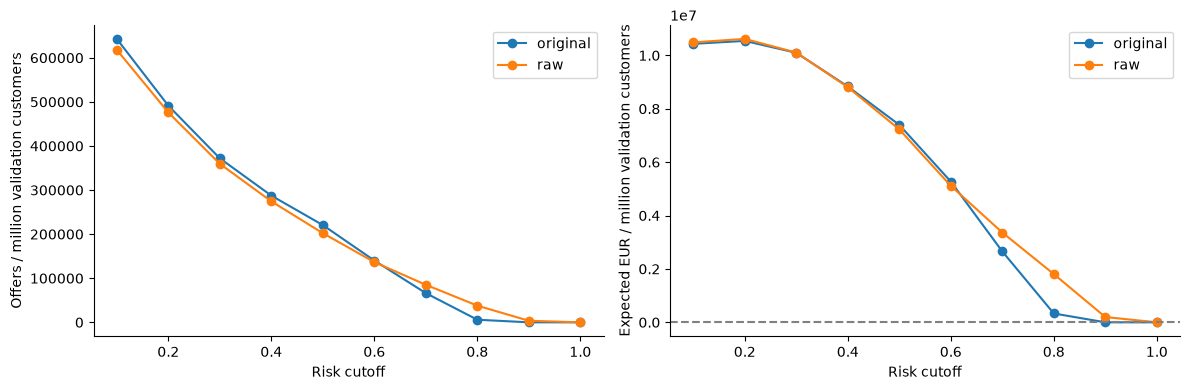

In [12]:
# Separate campaign reach from expected economic value.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Draw both models over the same cutoff grid.
for name in policy_names:
    # Select this model's actual validation totals.
    model_results = validation_raw[validation_raw['Model'] == name]
    # Convert totals using the validation denominator.
    table = per_million(model_results, len(y_valid))
    # Show that a 0.2 risk cutoff need not imply a 20% offer population.
    axes[0].plot(table['Cutoff'], table['Offers / million'], marker='o', label=name)
    # Show the calculated value, rather than choosing a cutoff from a visual impression alone.
    axes[1].plot(table['Cutoff'], table['Value EUR / million'], marker='o', label=name)
# State the unit and population for offer counts.
axes[0].set(xlabel='Risk cutoff', ylabel='Offers / million validation customers')
# State the economic reporting unit separately from the customer-count unit.
axes[1].set(xlabel='Risk cutoff', ylabel='Expected EUR / million validation customers')
# No offers is the zero incremental-impact reference.
axes[1].axhline(0, color='grey', linestyle='--')
# Identify the two models in both panels.
for ax in axes:
    # Keep names consistent with the metric and policy tables.
    ax.legend()
# Avoid labels overlapping the adjacent panel.
plt.tight_layout()
# Display the validation evidence used for the policy choices.
plt.show()

The main policy has **no contact cap**. A risk cutoff of 0.2 does not mean contacting 20% of customers. All customers whose predicted risk is at least 0.2 receive offers, even if this is nearly half the population. Under perfectly calibrated risk and these assumptions, the individual break-even risk is 10/(56+10), about 15.2%; the validation grid is coarser and realized samples vary. Which cutoff wins on validation, and how broad is the neighborhood of similar values?

## Refit once, keeping policy choices fixed
Refit the first model and selected finalist on all 5,634 development rows. If a correction was selected, its internal folds still use seed 606 and `ensemble=False`. Apply the already chosen cutoffs to the same 1,409 holdout customers. Do not revise choices after seeing the following results. This holdout was already inspected in classroom materials.

In [13]:
# Refit with all development rows while keeping correction and cutoff decisions fixed.
final_models = {}
# Store holdout probabilities in model order without using them to select a new policy.
prob_test = {}
# Keep each fixed policy's offer mask for all subsequent comparisons.
selections = {}
# Collect actual-sample campaign outcomes for audit.
test_rows = []
# Record holdout probability metrics separately from the economic accounting.
test_metric_rows = []
# Apply the two already selected policies to identical holdout customers.
for name in policy_names:
    # Clone removes fitting-only weights and preprocessing before the development refit.
    final_models[name] = clone(models[name]).fit(X_dev, y_dev)
    # Predict in X_test order; y_test uses that same customer order.
    prob_test[name] = final_models[name].predict_proba(X_test)[:, 1]
    # Apply the unchanged cutoff chosen on validation.
    selections[name] = prob_test[name] >= chosen_cutoffs[name]
    # Calculate incremental contribution under the fixed default assumptions.
    row = campaign(y_test, selections[name])
    # Keep the policy name on the resulting audit row.
    row['Model'] = name
    # Save raw campaign totals before per-million conversion.
    test_rows.append(row)
    # Holdout metrics describe probability/ranking performance, not a new selection step.
    test_metric_rows.append({'Model': name, 'Brier': brier_score_loss(y_test, prob_test[name]),
                             'AP': average_precision_score(y_test, prob_test[name])})
# Build the actual-sample table with model names as row labels.
test_raw = pd.DataFrame(test_rows).set_index('Model')
# Create an explicit policy that offers to nobody.
no_offers = np.zeros(len(y_test), dtype=bool)
# Retain missed churn in the reference while its incremental value remains zero.
test_raw.loc['No offers'] = pd.Series(campaign(y_test, no_offers))
# Normalize holdout totals with the holdout denominator.
display(per_million(test_raw, len(y_test)).round(3))
# Display probability metrics without scaling them to campaign size.
display(pd.DataFrame(test_metric_rows).set_index('Model').round(6))

,Offers / million,TP / million,FP / million,FN / million,Recall,Value EUR / million
Model,,,,,,
original,"486,160.3970","227,111.4270","259,048.9710","38,325.0530",0.8560,"10,127,750.1770"
raw,"478,353.4420","227,111.4270","251,242.0160","38,325.0530",0.8560,"10,205,819.7300"
No offers,0.0000,0.0000,0.0000,"265,436.4800",0.0000,0.0000


,Brier,AP
Model,,
original,0.1381,0.6338
raw,0.1342,0.6675


In [14]:
# Preserve customer identity alongside predictions so alignment can be audited directly.
audit = pd.DataFrame(index=X_test.index)
# Retrieve identifiers in the exact order sent into predict_proba.
audit['customerID'] = df.loc[X_test.index, 'customerID']
# pandas aligns the outcome labels by the same original row index.
audit['Churn'] = y_test
# Add both policies' predictions and decisions to the same customer rows.
for name in policy_names:
    # Confirm positional arrays have exactly one result per audit customer.
    assert len(prob_test[name]) == len(audit)
    # Store continuous probability separately from the binary offer decision.
    audit[name + ' probability'] = prob_test[name]
    # The mask corresponds to the fixed validation cutoff.
    audit[name + ' offer'] = selections[name]
# A duplicated customer would invalidate the intended customer-level comparison.
assert audit['customerID'].is_unique
# Confirm outcomes have neither changed nor been reordered during table construction.
assert audit['Churn'].equals(y_test)

## Isolate a capacity limit without changing anything else
Compare the same holdout, fitted model, chosen cutoff and response assumptions with and without a 20% cap. For the capped policy take the top `ceil(0.20 × n)` scores in descending order, then retain only those meeting the cutoff. Stable sorting breaks exact score ties by holdout row order. For n=1,409 this permits 282 offers. This ceil rule follows Session 6; notebook 08 used rounding on development.

In [15]:
# Retain both uncapped and capped actual-sample results.
capacity_rows = []
# Round up the 20% capacity as specified in Session 6, giving 282 of 1,409 customers.
capacity = int(np.ceil(.20 * len(y_test)))
# Keep the fitted model, cutoff, population and economics unchanged for each comparison.
for name in policy_names:
    # Negating scores sorts highest risk first; stable sorting keeps original order for ties.
    ranked_positions = np.argsort(-prob_test[name], kind='stable')
    # Restrict potential recipients to the available number of contact places.
    top_positions = ranked_positions[:capacity]
    # Start with no offers and fill only eligible places above the same cutoff.
    capped = np.zeros(len(y_test), dtype=bool)
    # A high ranking alone does not override the fixed risk cutoff.
    capped[top_positions] = selections[name][top_positions]
    # The capped policy cannot exceed its capacity.
    assert capped.sum() <= capacity
    # Every capped recipient must also be an uncapped recipient.
    assert np.all(~capped | selections[name])
    # Evaluate both offer masks with the identical economic formula.
    for rule, selected in [('Uncapped', selections[name]), ('20% cap', capped)]:
        # Calculate raw outcomes for this model/policy combination.
        row = campaign(y_test, selected)
        # Preserve model identity for the later paired comparison.
        row['Model'] = name
        # Label the only element that differs in this controlled comparison.
        row['Rule'] = rule
        # Save the actual-sample calculation.
        capacity_rows.append(row)
# Organize the four campaign results before display scaling.
capacity_raw = pd.DataFrame(capacity_rows)
# Use the same holdout denominator for capped and uncapped policies.
display(per_million(capacity_raw, len(y_test)).round(3))
# Put both models side by side under each capacity rule.
capacity_values = capacity_raw.pivot(index='Rule', columns='Model', values='Value EUR')
# Subtract values on the original sample before changing reporting units.
capacity_gap = capacity_values[selected_method] - capacity_values['original']
# Convert the difference using the same population size as both model estimates.
capacity_gap = capacity_gap * 1_000_000 / len(y_test)
# Label the direction and units so a positive value has an unambiguous interpretation.
display(capacity_gap.rename('Finalist advantage EUR / million'))

,Offers / million,TP / million,FP / million,FN / million,Recall,Value EUR / million,Model,Rule
0,"486,160.3970","227,111.4270","259,048.9710","38,325.0530",0.8560,"10,127,750.1770",original,Uncapped
1,"200,141.9450","132,008.5170","68,133.4280","133,427.9630",0.4970,"6,711,142.6540",original,20% cap
2,"478,353.4420","227,111.4270","251,242.0160","38,325.0530",0.8560,"10,205,819.7300",raw,Uncapped
3,"200,141.9450","136,266.8560","63,875.0890","129,169.6240",0.5130,"6,992,193.0450",raw,20% cap


Rule
20% cap    281,050.3903
Uncapped    78,069.5529
Name: Finalist advantage EUR / million, dtype: float64

Capacity changes which and how many customers receive an offer. The apparent model advantage can change when the policy changes; it is not an intrinsic euro value of the model. This is a diagnostic comparison, not a new holdout-based policy selection. Which policy reaches more churn, and does higher reach offset its extra discounts under the assumed responses?

## Paired uncertainty, conditional on the fixed policies
Resample holdout customers 4,000 times with seed 606. Each draw keeps the outcome and both policies' predictions together. Models, selected correction, cutoffs and economic assumptions stay fixed; no capacity restriction is used. Compute a conditional percentile interval for each policy and their paired difference. Scale both interval endpoints by exactly the same holdout factor as the point estimate.

In [16]:
# Retain the same holdout order for outcomes and both policies.
labels = y_test.to_numpy()
# Bootstrap this actual sample size, not a million artificial customers.
n = len(labels)
# Use one common conversion for point estimates and both interval endpoints.
factor = 1_000_000 / n
# Store each policy's expected contribution for each individual holdout row.
per_customer = {}
# These arrays encode fixed offer decisions and fixed response assumptions.
for name in policy_names:
    # An offered observed churner contributes +56; an offered observed stayer contributes -10.
    value_if_offered = np.where(labels == 1, 56., -10.)
    # Unoffered customers contribute zero relative to no intervention.
    per_customer[name] = selections[name] * value_if_offered
    # Confirm that row contributions reproduce the earlier campaign accounting.
    assert np.isclose(per_customer[name].sum(), test_raw.loc[name, 'Value EUR'])
# Pair both policy values before resampling to retain their customer-level dependence.
difference = per_customer[selected_method] - per_customer['original']
# Fix the random seed from the classroom protocol.
rng = np.random.default_rng(606)
# Allocate one total per bootstrap draw for each policy.
bootstrap_raw = {}
# Include the paired difference as well as each policy's total.
for name in policy_names + ['Difference']:
    # Values remain in actual-sample euros until the final reporting step.
    bootstrap_raw[name] = np.empty(4000)
# Resample customers with replacement while keeping models, cutoffs and assumptions fixed.
for draw in range(4000):
    # The same sampled positions must be used for both policies in this draw.
    sampled_positions = rng.integers(0, n, n)
    # Sum contributions from the sampled customer rows for each model.
    for name in policy_names:
        # Duplicated indices represent repeated draws of the same customer.
        bootstrap_raw[name][draw] = per_customer[name][sampled_positions].sum()
    # Compute the paired difference on exactly those same resampled customers.
    bootstrap_raw['Difference'][draw] = difference[sampled_positions].sum()
# Check that the direct paired calculation equals subtracting the paired campaign totals.
assert np.allclose(bootstrap_raw['Difference'], bootstrap_raw[selected_method]-bootstrap_raw['original'])

In [17]:
# Keep point estimates distinct from the mean of bootstrap draws.
point_raw = {}
# Original-sample totals are the reported central estimates.
for name in policy_names:
    # Sum the fixed per-customer expected contributions once on the actual holdout.
    point_raw[name] = per_customer[name].sum()
# Report the original paired difference, not a bootstrap-average replacement.
point_raw['Difference'] = difference.sum()
# The no-offer reference has zero incremental contribution in every draw.
point_raw['No offers'] = 0.
# Its bootstrap distribution is therefore identically zero under this definition.
bootstrap_raw['No offers'] = np.zeros(4000)
# Collect all conditional percentile intervals with a readable row-building loop.
interval_rows = []
# Include both policies, their difference and the zero reference.
for name, values in bootstrap_raw.items():
    # Take the central 95% using NumPy's default linear quantile interpolation.
    low, high = np.quantile(values, [.025, .975])
    # Keep estimates and both bounds in actual-sample euros for audit.
    interval_rows.append({'Policy': name, 'Estimate': point_raw[name],
                          'Low 2.5%': low, 'High 97.5%': high})
# Make policy names explicit row labels.
intervals_raw = pd.DataFrame(interval_rows).set_index('Policy')
# Scale all three numerical columns by the identical holdout factor.
intervals_per_million = intervals_raw * factor
# State the units and the conditional interpretation before the table.
print('Expected contribution and conditional 95% interval, EUR / million holdout customers')
# Retain useful precision while making the campaign comparison readable.
display(intervals_per_million.round(3))

Expected contribution and conditional 95% interval, EUR / million holdout customers


,Estimate,Low 2.5%,High 97.5%
Policy,,,
original,"10,127,750.1770","8,803,406.6710","11,429,666.4300"
raw,"10,205,819.7300","8,895,528.7440","11,500,425.8340"
Difference,"78,069.5530","-231,405.2520","401,703.3360"
No offers,0.0000,0.0000,0.0000


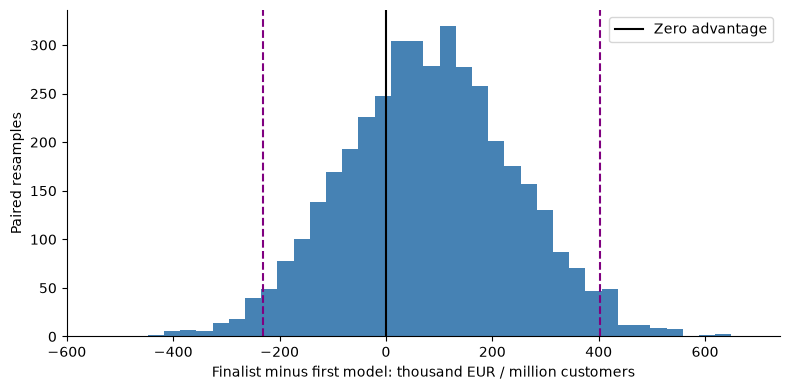

In [18]:
# Plot the paired difference distribution separately from the interval calculation.
fig, ax = plt.subplots(figsize=(8, 4))
# Thousands of euros per million customers keep horizontal labels short.
ax.hist(bootstrap_raw['Difference'] * factor / 1000, bins=40, color='steelblue')
# Show where the new policy has no incremental advantage over the first model.
ax.axvline(0, color='black', label='Zero advantage')
# Mark both endpoints from the same calculated percentile interval.
for bound in intervals_per_million.loc['Difference', ['Low 2.5%', 'High 97.5%']]:
    # Convert euro endpoints to the thousands-of-euros plotting unit too.
    ax.axvline(bound/1000, color='purple', linestyle='--')
# Specify the direction of subtraction and the reporting population.
ax.set(xlabel='Finalist minus first model: thousand EUR / million customers', ylabel='Paired resamples')
# Label the no-advantage reference.
ax.legend()
# Avoid cutting off the long reporting-unit label.
plt.tight_layout()
# Display the conditional uncertainty without implying causal offer-effect evidence.
plt.show()

This interval reflects evaluation-customer composition, conditional on the fitted policies and response assumptions. It omits the full retraining and selection process, future population shifts, and uncertainty about the causal effect of the offer. Crossing zero allows either direction of advantage; it does not establish equality. Extrapolation to a million changes units, not statistical precision.

## Reconcile with v4 without changing calculated results
The following classroom numbers are verification targets only. The CSV hash and protocol match; v4 used scikit-learn 1.8.0, while this repository requires >=1.9 for earlier target-encoding lessons. Versions are printed above. Library-level numerical differences can change customers close to a cutoff; inspect policy counts and selected methods before attributing any discrepancy solely to a library version.

In [19]:
# These classroom sample totals are comparison targets only, not calculation inputs.
class_reference = pd.Series({'original': 14270., 'raw': 14380., 'Difference': 110.}) * factor
# Retrieve calculated estimates without modifying the model outputs.
calculated = intervals_per_million.loc[['original', selected_method, 'Difference'], 'Estimate'].copy()
# Use a common finalist label for this side-by-side reference comparison.
calculated.index = ['original', 'raw', 'Difference']
# Align reference and calculation by their labelled rows.
comparison = pd.DataFrame({'Calculated EUR / million': calculated, 'Class EUR / million': class_reference})
# Subtract named columns rather than relying on their physical position in the table.
comparison['Difference from class'] = comparison['Calculated EUR / million'] - comparison['Class EUR / million']
# Display numerical discrepancies instead of substituting reference values.
display(comparison.round(6))
# Convert both classroom interval endpoints using the same holdout denominator.
class_bounds = np.array([-326.05, 566.]) * factor
# Retrieve both calculated endpoints in their explicit lower/upper order.
calculated_bounds = intervals_per_million.loc['Difference', ['Low 2.5%', 'High 97.5%']].to_numpy()
# Keep the interval comparison separate from the central estimate comparison.
bound_check = pd.DataFrame({'Calculated EUR / million': calculated_bounds,
                            'Class EUR / million': class_bounds}, index=['Low 2.5%', 'High 97.5%'])
# Show any endpoint discrepancy at the same precision as the central estimates.
display(bound_check.round(6))
# Report the validation choices needed to understand agreement or disagreement with class.
print('Selected method:', selected_method, '; fixed cutoffs:', chosen_cutoffs)

,Calculated EUR / million,Class EUR / million,Difference from class
original,"10,127,750.1774","10,127,750.1774",0.0000
raw,"10,205,819.7303","10,205,819.7303",0.0000
Difference,"78,069.5529","78,069.5529",0.0000


,Calculated EUR / million,Class EUR / million
Low 2.5%,"-231,405.2520","-231,405.2520"
High 97.5%,"401,703.3357","401,703.3357"


Selected method: raw ; fixed cutoffs: {'original': 0.2, 'raw': 0.2}


## Sensitivity is not a confidence interval
Change one economic assumption at a time with models, selections and customers fixed. Retention efficacy, stayer acceptance and contact cost affect both policies. Switching cost applies only to the finalist when replacing the current strategy and is specified **per million eligible customers**; convert it to the actual holdout campaign before calculation. The sample default is zero. These scenario ranges are not probabilities or estimated confidence limits.

In [20]:
# Each tuple states: scenario, retention efficacy, stayer acceptance, contact cost, switching cost.
# Contact cost is per offer; switching cost is per million eligible customers.
scenarios = [('Default', .2, .5, 0., 0.),
             ('Retention 10%', .1, .5, 0., 0.), ('Retention 30%', .3, .5, 0., 0.),
             ('Stayer acceptance 25%', .2, .25, 0., 0.), ('Stayer acceptance 75%', .2, .75, 0., 0.),
             ('Contact EUR 1', .2, .5, 1., 0.), ('Contact EUR 5', .2, .5, 5., 0.),
             ('Switch EUR 100k / million', .2, .5, 0., 100_000.),
             ('Switch EUR 500k / million', .2, .5, 0., 500_000.)]
# Store one comparison row per one-way change of assumptions.
sensitivity_rows = []
# Keep holdout customers, fitted models and offer masks fixed throughout this exercise.
for scenario, effect, acceptance, contact, switch_per_million in scenarios:
    # Collect both policies' values under exactly the same response assumptions.
    values = {}
    # Revalue the fixed offer decisions without choosing new cutoffs.
    for name in policy_names:
        # The current strategy has no switching cost relative to itself.
        actual_switch = 0.
        # Charge the replacement strategy's implementation cost only to the finalist.
        if name == selected_method:
            # Convert the million-customer quote to this actual-sample campaign.
            actual_switch = switch_per_million / factor
        # Recalculate contribution using the changed assumptions, not simulated outcomes.
        result = campaign(y_test, selections[name], effect, acceptance, contact, actual_switch)
        # Convert each campaign value back to the common reporting basis.
        values[name] = result['Value EUR'] * factor
    # Compare values on the same population and in identical units.
    sensitivity_rows.append({'Scenario': scenario, 'First EUR / million': values['original'],
                              'Finalist EUR / million': values[selected_method],
                              'Advantage EUR / million': values[selected_method]-values['original']})
# Display scenario changes without presenting them as confidence intervals.
display(pd.DataFrame(sensitivity_rows).set_index('Scenario').round(2))

,First EUR / million,Finalist EUR / million,Advantage EUR / million
Scenario,,,
Default,"10,127,750.1800","10,205,819.7300","78,069.5500"
Retention 10%,"3,768,630.2300","3,846,699.7900","78,069.5500"
Retention 30%,"16,486,870.1200","16,564,939.6700","78,069.5500"
Stayer acceptance 25%,"11,422,995.0300","11,462,029.8100","39,034.7800"
Stayer acceptance 75%,"8,832,505.3200","8,949,609.6500","117,104.3300"
Contact EUR 1,"9,641,589.7800","9,727,466.2900","85,876.5100"
Contact EUR 5,"7,696,948.1900","7,814,052.5200","117,104.3300"
Switch EUR 100k / million,"10,127,750.1800","10,105,819.7300","-21,930.4500"
Switch EUR 500k / million,"10,127,750.1800","9,705,819.7300","-421,930.4500"


**Observation:** Use the calculated advantage and its conditional interval together; neither demonstrates that offers actually prevent churn. **Hypothesis:** The new policy may improve incremental margin under the response assumptions. **Decision:** A small uncertain gain may not justify switching costs. **Question:** What plausible response or cost assumption reverses your preferred policy?

## A concrete experiment before changing the retention policy
Randomize eligible customers 50/50 **before either policy selects recipients**. Arm A applies the current original-input model and its fixed cutoff; arm B applies the finalist and its fixed cutoff. Keep eligibility, contact period and offer terms comparable. Predefine the observation window (for example 90 days), customer-level realized margin net of discounts, contact and operating costs, and the minimum useful gain before launch. Compare average net contribution **per eligible customer**, including customers who receive no offer, with uncertainty based on the randomization unit. Scale the estimated difference to a million only for reporting.

This current-versus-new comparison is an A/B test of entire policies. Randomizing offer/no offer **within a selected population** instead estimates an offer effect for that selected population; it does not by itself compare the two whole selection strategies. A before/after comparison is exposed to seasonality, pricing and changing customer mix. Do not report an assumed or simulated retention effect as an observed experiment result.

Session 7 asks why the models disagree on individual customers and contract groups. Session 8 checks input schema and missingness, then monitors calibration, detection, contact volume and realized incremental value by group. Outcomes arrive with delay; investigate drift and evaluate policy changes independently instead of repeatedly optimizing on this classroom holdout.

**Takeaway:** A probability becomes a decision only through a policy and assumptions. Keep the zero reference, distinguish risk cutoff from contact capacity, pair the comparison and measure causal policy value in a randomized campaign.

### Read the executed evidence and version comparison
Both policies choose cutoff 0.2. The first model produces about EUR 10,127,750.18 per million holdout customers and the raw finalist EUR 10,205,819.73. Their paired difference is EUR +78,069.55, with a conditional 95% interval from EUR -231,405.25 to +401,703.34 per million. The interval includes losses; the point estimate alone does not establish a useful improvement.

Both policies reach the same number of observed churns on this holdout. The finalist's uncapped advantage comes from fewer offers to observed stayers. Consequently, changing retention efficacy shifts both policies' values equally in the one-way sensitivity table, while changing stayer acceptance changes their gap. A switching cost of EUR 100,000 per million exceeds the central gain. With the 20% cap, the apparent advantage rises to about EUR 281,050.39 per million, but both policies reach less churn and have lower total expected contribution under these assumptions. Capacity changes the decision problem.

The executed Python 3.12.9 / scikit-learn 1.9.1 / NumPy 2.5.3 / pandas 3.0.6 environment differs from class (scikit-learn 1.8.0 / NumPy 2.4.1 / pandas 2.3.3). Dataset identity, selected method, cutoffs, group detection checks, campaign values and paired economic interval endpoints reproduce the v4 reference to displayed precision. No results were manually substituted. Small continuous probability differences can remain even when threshold-based campaign results match. This classroom reuse still needs a new randomized policy experiment before treating the gain as causal evidence.